<a href="https://colab.research.google.com/github/slvmayank/mnist10oc/blob/new/mnsit10oc.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from urllib.request import urlretrieve
from pathlib import Path
import cv2

In [6]:
url= "https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz"
fname= 'mnist.npz'

urlretrieve(url, fname)

obj= np.load(fname)
dir(obj)

['_MAX_REPR_ARRAY_COUNT',
 '__abstractmethods__',
 '__class__',
 '__class_getitem__',
 '__contains__',
 '__del__',
 '__delattr__',
 '__dict__',
 '__dir__',
 '__doc__',
 '__enter__',
 '__eq__',
 '__exit__',
 '__firstlineno__',
 '__format__',
 '__ge__',
 '__getattribute__',
 '__getitem__',
 '__getstate__',
 '__gt__',
 '__hash__',
 '__init__',
 '__init_subclass__',
 '__iter__',
 '__le__',
 '__len__',
 '__lt__',
 '__module__',
 '__ne__',
 '__new__',
 '__reduce__',
 '__reduce_ex__',
 '__repr__',
 '__reversed__',
 '__setattr__',
 '__sizeof__',
 '__slots__',
 '__static_attributes__',
 '__str__',
 '__subclasshook__',
 '__weakref__',
 '_abc_impl',
 '_files',
 'allow_pickle',
 'close',
 'f',
 'fid',
 'files',
 'get',
 'items',
 'keys',
 'max_header_size',
 'pickle_kwargs',
 'values',
 'zip']

***EXPLORING DATASET***

In [7]:
obj.files

['x_test', 'x_train', 'y_train', 'y_test']

In [8]:
x_train= obj['x_train']
y_train= obj['y_train']
x_train.shape
type(x_train)

numpy.ndarray

In [9]:
x_train.nbytes/(1024 ** 2)

44.86083984375

In [10]:
obj['x_train'][:10]
obj['y_train'][:20]

array([5, 0, 4, 1, 9, 2, 1, 3, 1, 4, 3, 5, 3, 6, 1, 7, 2, 8, 6, 9],
      dtype=uint8)

In [11]:
np.unique(obj['y_train'], return_counts=True)

(array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9], dtype=uint8),
 array([5923, 6742, 5958, 6131, 5842, 5421, 5918, 6265, 5851, 5949]))

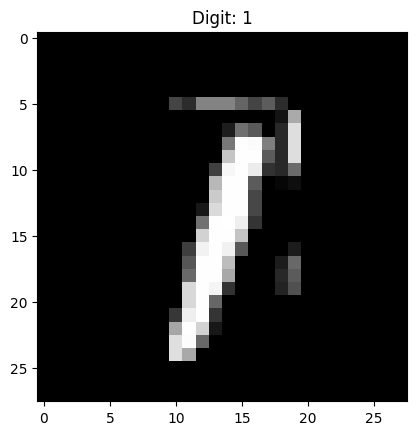

In [12]:
plt.imshow(x_train[67], cmap='gray')
plt.title(f"Digit: {y_train[67]}")
plt.show()

In [13]:
x_train.max()

np.uint8(255)

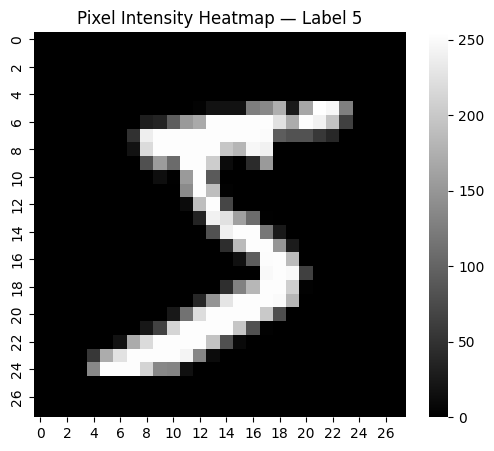

In [14]:
import seaborn as sns
plt.figure(figsize=(6, 5))

sns.heatmap(x_train[0], cmap="gray", cbar=True)

plt.title(f"Pixel Intensity Heatmap — Label {y_train[0]}")
plt.show()

**PREPROCESSING**

In [15]:
#nomalization of pixel vals

normx_train= x_train.astype('float')/ 255.0
normx_train.max()

np.float64(1.0)

In [16]:
np.random.choice(normx_train.ravel(), size=20)

array([0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.24705882, 0.        , 0.        , 0.        , 0.98823529,
       0.        , 0.        , 0.04313725, 0.        , 0.        ])

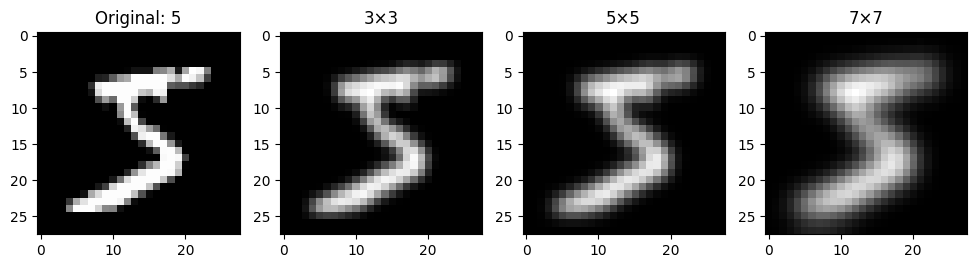

In [17]:
#gaussian bulr
blur_3 = cv2.GaussianBlur(x_train[0], (3, 3), 0)
blur_5 = cv2.GaussianBlur(x_train[0], (5, 5), 0)
blur_7 = cv2.GaussianBlur(x_train[0], (9, 9), 0)

fig, axes = plt.subplots(1, 4, figsize=(12, 3))

images = [x_train[0], blur_3, blur_5, blur_7]
titles = [f"Original: {y_train[0]}", "3×3", "5×5", "7×7"]

for ax, img, title in zip(axes, images, titles):
    ax.imshow(img, cmap="gray")
    ax.set_title(title)

plt.show()

In [20]:
#image resize
img= x_train[0]
resized= cv2.resize(img, (20, 20))

print("origianl size: ", x_train[0].shape)
resized

origianl size:  (28, 28)


array([[  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   6,   7,  33,  54,
         46,  55, 101,  70,   0,   0,   0],
       [  0,   0,   0,   0,   0,   5,  27,  75, 128, 192, 206, 219, 229,
        186, 217, 237, 128,   0,   0,   0],
       [  0,   0,   0,   0,   0,  81, 245, 253, 253, 253, 241, 246, 249,
         71,  66,  42,  12,   0,   0,   0],
       [  0,   0,   0,   0,   0,  33, 171, 165, 253, 230,  83, 104, 189,
          0,   0,   0,   0,   0,   0,   0],
       [  0,   0,   0,   0,   0,   0,   8,   1, 194, 123,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0, 144, 218,  23,   0,   0,
          0,   0,   0,   0,   0,   0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,  28, 208, 181, 103,   1,
          0,   0,   0,   0,   0,   0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,  52, 209, 248, 146,
         32,   1,   0,   0,   0,   0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,  31, 128, 252,
        176,  24,   0,   0,   0,   0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0, 249,
        251, 101,   0,   0,   0,   0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   6,  50, 131, 198, 253,
        230,  40,   0,   0,   0,   0,   0],
       [  0,   0,   0,   0,   0,   0,   0,  19, 128, 222, 249, 253, 211,
         82,   7,   0,   0,   0,   0,   0],
       [  0,   0,   0,   0,   3,  40,  87, 221, 253, 244, 207, 103,   2,
          0,   0,   0,   0,   0,   0,   0],
       [  0,   0,   0,  61, 135, 224, 247, 253, 221, 104,  26,   1,   0,
          0,   0,   0,   0,   0,   0,   0],
       [  0,   0,   0, 183, 253, 245, 166, 132,  10,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0]], dtype=uint8)

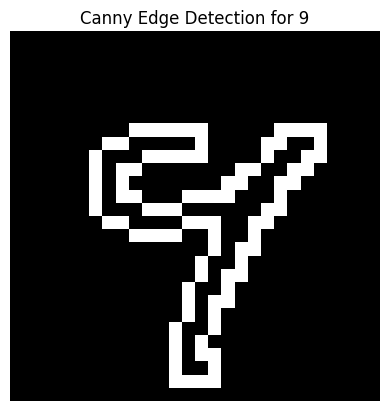

In [21]:
#edge detection
img = x_train[54]

edges = cv2.Canny(img, 100, 200)

plt.imshow(edges, cmap="gray")
plt.title(f"Canny Edge Detection for {y_train[57]}")
plt.axis("off")
plt.show()